# Rice Grain Classification

## 0. GPU Check

In [1]:
import torch

if torch.cuda.is_available():
    print(f"GPU ready: {torch.cuda.get_device_name(0)}")
    print(f"CUDA version : {torch.version.cuda}")
    print(f"cuDNN version: {torch.backends.cudnn.version()}")
    DEVICE = torch.device('cuda')
else:
    print("NO GPU DETECTED")
    DEVICE = torch.device('cpu')

print(f"\nUsing device: {DEVICE}")

GPU ready: NVIDIA GeForce RTX 3060
CUDA version : 12.1
cuDNN version: 90100

Using device: cuda


## 1. Imports

In [2]:
import os, cv2, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as mpl_cm
import seaborn as sns
from glob import glob
from collections import Counter
from scipy import stats
warnings.filterwarnings('ignore')

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast  # Mixed-precision

# torchvision
import torchvision.models as tv_models
import torchvision.transforms as T

# timm — gives us Xception and InceptionResNetV2
try:
    import timm
    HAS_TIMM = True
except ImportError:
    HAS_TIMM = False
    print("timm not installed — Xception / InceptionResNetV2 will be skipped.")
    print("Install with: pip install timm")

# sklearn metrics
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Imports done.')

Imports done.


## 2. Configuration

In [3]:
# Two separate folders — Augmented for train/val, Original for test
AUG_DIR    = 'Rice Images/Augmented_images'
ORIG_DIR   = 'Rice Images/Original_Images'
OUTPUT_DIR = './outputs'

IMG_SIZE    = (224, 224)
BATCH_SIZE  = 32
EPOCHS      = 20      # Early stopping will halt training when val_acc plateaus
LR          = 1e-4
NUM_WORKERS = 4

for d in [OUTPUT_DIR,
          os.path.join(OUTPUT_DIR, 'models'),
          os.path.join(OUTPUT_DIR, 'gradcam'),
          os.path.join(OUTPUT_DIR, 'lime')]:
    os.makedirs(d, exist_ok=True)

# Class names derived from Augmented folder (same structure in both)
CLASS_NAMES = sorted([
    d for d in os.listdir(AUG_DIR)
    if os.path.isdir(os.path.join(AUG_DIR, d))
])
NUM_CLASSES = len(CLASS_NAMES)
print('Classes:', CLASS_NAMES)
print('Num classes:', NUM_CLASSES)

# -----------------------------------------------------------------------
# Model configs: (torchvision/timm builder fn, mean, std, input size)
# Each model has its OWN ImageNet normalisation — this is the critical fix.
# -----------------------------------------------------------------------
# Standard ImageNet stats
_MEAN = [0.485, 0.456, 0.406]
_STD  = [0.229, 0.224, 0.225]
# Inception-family uses different stats
_MEAN_INC = [0.5, 0.5, 0.5]
_STD_INC  = [0.5, 0.5, 0.5]

MODEL_CONFIGS = {
    'EfficientNetB0':    ('efficientnet_b0',    _MEAN,     _STD,     224),
    'MobileNetV2':       ('mobilenet_v2',        _MEAN,     _STD,     224),
    'VGG16':             ('vgg16',               _MEAN,     _STD,     224),
    'InceptionV3':       ('inception_v3',        _MEAN_INC, _STD_INC, 299),
}

if HAS_TIMM:
    MODEL_CONFIGS['Xception']          = ('xception',              _MEAN_INC, _STD_INC, 299)
    MODEL_CONFIGS['InceptionResNetV2'] = ('inception_resnet_v2',   _MEAN_INC, _STD_INC, 299)

Classes: ['Aush', 'BR-28', 'BR-29', 'Beroi', 'Chinigura', 'Ghee Bhog', 'Katari Najir', 'Katari Siddho', 'Miniket', 'Swarna']
Num classes: 10


## 3. Load Paths

In [4]:
def get_paths_labels(data_dir, class_names):
    paths, labels = [], []
    for idx, cls in enumerate(class_names):
        folder = os.path.join(data_dir, cls)
        for ext in ('*.jpg','*.jpeg','*.png','*.bmp',
                    '*.JPG','*.JPEG','*.PNG','*.BMP'):
            for fp in glob(os.path.join(folder, ext)):
                paths.append(fp)
                labels.append(idx)
    return np.array(paths), np.array(labels)

# Augmented images  → train + val  (no contamination risk)
aug_paths,  aug_labels  = get_paths_labels(AUG_DIR,  CLASS_NAMES)
# Original images   → test only    (clean, never seen during training)
orig_paths, orig_labels = get_paths_labels(ORIG_DIR, CLASS_NAMES)

print(f'Augmented images (train+val): {len(aug_paths)}')
print(f'Original  images (test only): {len(orig_paths)}')
for i, cls in enumerate(CLASS_NAMES):
    print(f'  {cls}: aug={( aug_labels==i).sum()}  orig={(orig_labels==i).sum()}')

Augmented images (train+val): 8000
Original  images (test only): 2000
  Aush: aug=800  orig=200
  BR-28: aug=800  orig=200
  BR-29: aug=800  orig=200
  Beroi: aug=800  orig=200
  Chinigura: aug=800  orig=200
  Ghee Bhog: aug=800  orig=200
  Katari Najir: aug=800  orig=200
  Katari Siddho: aug=800  orig=200
  Miniket: aug=800  orig=200
  Swarna: aug=800  orig=200


## 4. Preprocessing

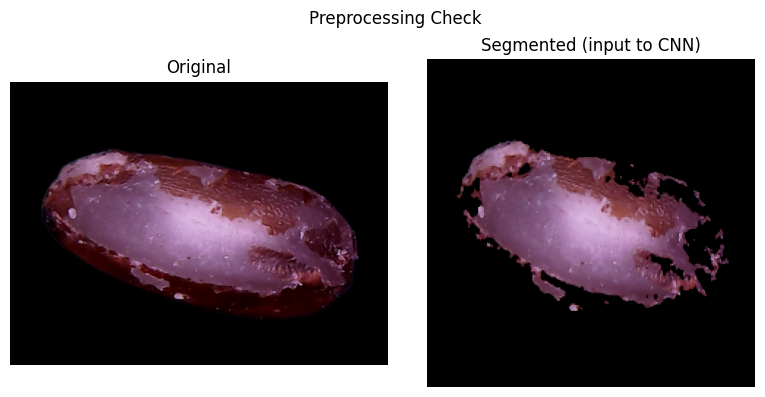

Segmented image shape: (224, 224, 3) | dtype: uint8


In [5]:
def segment_grain(image_path):
    """
    Segments the rice grain from black background.
    Returns uint8 RGB image [0-255] sized to IMG_SIZE.
    """
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f'Cannot read: {image_path}')

    # Grayscale + Otsu binarization
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, binary = cv2.threshold(gray, 0, 255,
                               cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Morphological cleanup
    kernel = np.ones((3, 3), np.uint8)
    cleaned = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=2)
    cleaned = cv2.medianBlur(cleaned, 5)

    # Apply mask to colour image
    mask3   = cv2.cvtColor(cleaned, cv2.COLOR_GRAY2BGR)
    segment = cv2.bitwise_and(img, mask3)

    # Resize and convert to RGB
    segment = cv2.resize(segment, IMG_SIZE)
    segment = cv2.cvtColor(segment, cv2.COLOR_BGR2RGB)
    return segment  # uint8 [0-255]


# Visualise preprocessing stages
sample = aug_paths[0]
orig   = cv2.cvtColor(cv2.imread(sample), cv2.COLOR_BGR2RGB)
seg    = segment_grain(sample)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(orig); axes[0].set_title('Original'); axes[0].axis('off')
axes[1].imshow(seg);  axes[1].set_title('Segmented (input to CNN)'); axes[1].axis('off')
plt.suptitle('Preprocessing Check', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'preprocessing_check.png'), dpi=150)
plt.show()
print('Segmented image shape:', seg.shape, '| dtype:', seg.dtype)

## 5. Build Dataset

In [6]:
def build_dataset(paths, labels, desc=''):
    X, y, failed = [], [], []
    total = len(paths)
    for i, (p, l) in enumerate(zip(paths, labels)):
        try:
            X.append(segment_grain(p))
            y.append(l)
        except Exception as e:
            failed.append((p, str(e)))
        if (i + 1) % 500 == 0:
            print(f'  {i+1}/{total}')
    if failed:
        print(f'Failed: {len(failed)} images')
    return np.array(X, dtype=np.uint8), np.array(y, dtype=np.int64)

# Build augmented dataset (train + val)
print('Building augmented dataset (train+val)...')
X_aug, y_aug = build_dataset(aug_paths, aug_labels)
print(f'Done. Shape: {X_aug.shape} | dtype: {X_aug.dtype}')
print(f'Memory: {X_aug.nbytes / 1e6:.0f} MB')

# Build original dataset (test)
print('\nBuilding original dataset (test)...')
X_test_all, y_test_all = build_dataset(orig_paths, orig_labels)
print(f'Done. Shape: {X_test_all.shape} | dtype: {X_test_all.dtype}')
print(f'Memory: {X_test_all.nbytes / 1e6:.0f} MB')

Building augmented dataset (train+val)...
  500/8000
  1000/8000
  1500/8000
  2000/8000
  2500/8000
  3000/8000
  3500/8000
  4000/8000
  4500/8000
  5000/8000
  5500/8000
  6000/8000
  6500/8000
  7000/8000
  7500/8000
  8000/8000
Done. Shape: (8000, 224, 224, 3) | dtype: uint8
Memory: 1204 MB

Building original dataset (test)...
  500/2000
  1000/2000
  1500/2000
  2000/2000
Done. Shape: (2000, 224, 224, 3) | dtype: uint8
Memory: 301 MB


## 6. Train / Val Split  +  Test Set Assignment

In [7]:
# Split augmented images into train and val (stratified)
X_train, X_val, y_train, y_val = train_test_split(
    X_aug, y_aug, test_size=0.176, stratify=y_aug, random_state=SEED)

# Test set = ALL original images (zero contamination guaranteed)
X_test, y_test = X_test_all, y_test_all

print(f'Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')
print('  (Test set = original images only — no augmented copies included)')
for name, lbls in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    c = Counter(lbls)
    print(f'  {name}: {[c[i] for i in range(NUM_CLASSES)]}')

Train: 6592 | Val: 1408 | Test: 2000
  (Test set = original images only — no augmented copies included)
  Train: [659, 660, 659, 659, 659, 659, 659, 659, 660, 659]
  Val: [141, 140, 141, 141, 141, 141, 141, 141, 140, 141]
  Test: [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]


## 7. PyTorch Dataset & DataLoader

In [8]:
class RiceDataset(Dataset):
    """PyTorch dataset for rice grain images."""

    def __init__(self, images, labels, transform=None):
        self.images    = images    # uint8 numpy (N, H, W, 3)
        self.labels    = labels    # int64 numpy (N,)
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img   = self.images[idx]          # (H, W, 3) uint8
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label


def make_transforms(mean, std, input_size, train=True):
    """Return torchvision transforms for a specific model."""
    size = input_size if isinstance(input_size, int) else input_size[0]
    if train:
        return T.Compose([
            T.ToPILImage(),
            T.Resize((size, size)),
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip(),
            T.RandomRotation(45),
            T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            T.RandomAffine(degrees=0, translate=(0.1, 0.1),
                           scale=(0.85, 1.15), shear=10),
            T.ToTensor(),
            T.Normalize(mean=mean, std=std),
        ])
    else:
        return T.Compose([
            T.ToPILImage(),
            T.Resize((size, size)),
            T.ToTensor(),
            T.Normalize(mean=mean, std=std),
        ])


def make_loaders(model_name):
    """Create train / val / test DataLoaders for a given model."""
    _, mean, std, inp_size = MODEL_CONFIGS[model_name]

    train_ds = RiceDataset(X_train, y_train,
                            transform=make_transforms(mean, std, inp_size, train=True))
    val_ds   = RiceDataset(X_val,   y_val,
                            transform=make_transforms(mean, std, inp_size, train=False))
    test_ds  = RiceDataset(X_test,  y_test,
                            transform=make_transforms(mean, std, inp_size, train=False))

    pin = DEVICE.type == 'cuda'
    train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin, drop_last=True)
    val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=pin)
    test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=pin)
    return train_dl, val_dl, test_dl

print('Dataset / DataLoader helpers ready.')

Dataset / DataLoader helpers ready.


## 8. Model Builder

In [9]:
def build_model(model_name, num_classes):
    """
    Returns a torchvision/timm model adapted for `num_classes`.
    BatchNorm layers are kept in eval mode (frozen stats) as in the original.
    """
    arch = MODEL_CONFIGS[model_name][0]  # string key

    # ---- torchvision models ----
    if arch == 'efficientnet_b0':
        m = tv_models.efficientnet_b0(weights='IMAGENET1K_V1')
        in_feat = m.classifier[1].in_features
        m.classifier = nn.Sequential(
            nn.BatchNorm1d(in_feat),
            nn.Linear(in_feat, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    elif arch == 'mobilenet_v2':
        m = tv_models.mobilenet_v2(weights='IMAGENET1K_V1')
        in_feat = m.classifier[1].in_features
        m.classifier = nn.Sequential(
            nn.BatchNorm1d(in_feat),
            nn.Linear(in_feat, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    elif arch == 'vgg16':
        m = tv_models.vgg16(weights='IMAGENET1K_V1')
        in_feat = m.classifier[0].in_features
        m.classifier = nn.Sequential(
            nn.Linear(in_feat, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    elif arch == 'inception_v3':
        m = tv_models.inception_v3(weights='IMAGENET1K_V1', aux_logits=True)
        # Replace both main and aux classifiers
        in_feat = m.fc.in_features
        m.fc = nn.Sequential(
            nn.BatchNorm1d(in_feat),
            nn.Linear(in_feat, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
        m.AuxLogits.fc = nn.Linear(m.AuxLogits.fc.in_features, num_classes)

    elif HAS_TIMM and arch in ('xception', 'inception_resnet_v2'):
        m = timm.create_model(arch, pretrained=True, num_classes=0, global_pool='avg')
        in_feat = m.num_features
        m.head = nn.Sequential()
        # Wrap in a container so we can attach our head
        class TimmWrapper(nn.Module):
            def __init__(self, backbone, head):
                super().__init__()
                self.backbone = backbone
                self.head     = head
            def forward(self, x):
                return self.head(self.backbone(x))
        head = nn.Sequential(
            nn.BatchNorm1d(in_feat),
            nn.Linear(in_feat, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
        m = TimmWrapper(m, head)
    else:
        raise ValueError(f'Unknown arch: {arch}')

    # Freeze BatchNorm running stats (keep BN in eval mode during forward)
    # This mirrors the Keras `layer.trainable = False` on BN layers.
    def freeze_bn(module):
        for mod in module.modules():
            if isinstance(mod, (nn.BatchNorm2d, nn.BatchNorm1d)):
                mod.eval()
                for p in mod.parameters():
                    p.requires_grad_(False)

    m.apply(freeze_bn)
    # But allow the NEW head's BN to train
    # (they don't have pretrained stats)
    if hasattr(m, 'classifier'):
        for mod in m.classifier.modules():
            if isinstance(mod, nn.BatchNorm1d):
                mod.train()
                for p in mod.parameters():
                    p.requires_grad_(True)
    if hasattr(m, 'fc'):
        for mod in m.fc.modules():
            if isinstance(mod, nn.BatchNorm1d):
                mod.train()
                for p in mod.parameters():
                    p.requires_grad_(True)
    if hasattr(m, 'head'):
        for mod in m.head.modules():
            if isinstance(mod, nn.BatchNorm1d):
                mod.train()
                for p in mod.parameters():
                    p.requires_grad_(True)

    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'  Trainable params: {trainable:,}')
    return m

print('Model builder ready.')

Model builder ready.


## 9. Training Loop

In [10]:
def train_model(model_name):
    print(f'\n{"="*55}')
    print(f'  {model_name}')
    print(f'{"="*55}')

    train_dl, val_dl, _ = make_loaders(model_name)
    model = build_model(model_name, NUM_CLASSES).to(DEVICE)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),
                           lr=LR, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=3, min_lr=1e-7, verbose=True)

    # Mixed-precision scaler (disabled on CPU)
    use_amp = DEVICE.type == 'cuda'
    scaler  = GradScaler(enabled=use_amp)

    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_val_acc  = 0.0
    patience_cnt  = 0
    PATIENCE      = 7
    best_path     = os.path.join(OUTPUT_DIR, 'models', f'{model_name}_best.pt')

    is_inception = MODEL_CONFIGS[model_name][0] == 'inception_v3'

    for epoch in range(1, EPOCHS + 1):
        # ---- Training ----
        model.train()
        # Keep pretrained BN in eval mode
        for mod in model.modules():
            if isinstance(mod, nn.BatchNorm2d):
                mod.eval()

        train_loss = train_correct = train_total = 0
        for imgs, labels in train_dl:
            imgs   = imgs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad()
            with autocast(enabled=use_amp):
                if is_inception:
                    outputs, aux = model(imgs)   # InceptionV3 returns (main, aux)
                    loss = criterion(outputs, labels) + 0.3 * criterion(aux, labels)
                else:
                    outputs = model(imgs)
                    loss    = criterion(outputs, labels)

            scaler.scale(loss).backward()
            # Gradient clipping (like clipnorm=1.0 in Keras Adam)
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                filter(lambda p: p.requires_grad, model.parameters()), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            train_loss    += loss.item() * imgs.size(0)
            preds          = outputs.argmax(dim=1)
            train_correct += (preds == labels).sum().item()
            train_total   += imgs.size(0)

        epoch_loss = train_loss / train_total
        epoch_acc  = train_correct / train_total

        # ---- Validation ----
        model.eval()
        val_loss = val_correct = val_total = 0
        with torch.no_grad():
            for imgs, labels in val_dl:
                imgs   = imgs.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                with autocast(enabled=use_amp):
                    outputs = model(imgs)
                    if isinstance(outputs, tuple):   # safety
                        outputs = outputs[0]
                    loss = criterion(outputs, labels)
                val_loss    += loss.item() * imgs.size(0)
                preds        = outputs.argmax(dim=1)
                val_correct += (preds == labels).sum().item()
                val_total   += imgs.size(0)

        epoch_val_loss = val_loss / val_total
        epoch_val_acc  = val_correct / val_total

        history['loss'].append(epoch_loss)
        history['accuracy'].append(epoch_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_accuracy'].append(epoch_val_acc)

        print(f'Epoch {epoch:3d}/{EPOCHS}  '
              f'loss={epoch_loss:.4f}  acc={epoch_acc:.4f}  '
              f'val_loss={epoch_val_loss:.4f}  val_acc={epoch_val_acc:.4f}')

        scheduler.step(epoch_val_acc)

        # Early stopping
        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            torch.save(model.state_dict(), best_path)
            print(f'  → saved best model (val_acc={best_val_acc:.4f})')
            patience_cnt = 0
        else:
            patience_cnt += 1
            if patience_cnt >= PATIENCE:
                print(f'  Early stop at epoch {epoch} (no improvement for {PATIENCE} epochs)')
                break

    # Restore best weights
    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    print(f'  Best val_accuracy: {best_val_acc:.4f}')
    torch.save(model.state_dict(), os.path.join(OUTPUT_DIR, 'models', f'{model_name}_final.pt'))
    return model, history


print('Trainer ready.')

Trainer ready.


## 10. Train EfficientNetB0 First
Confirm the pipeline works before running all models.


  EfficientNetB0
  Trainable params: 4,757,862
Epoch   1/20  loss=0.8637  acc=0.7377  val_loss=0.2481  val_acc=0.9226
  → saved best model (val_acc=0.9226)
Epoch   2/20  loss=0.2853  acc=0.8976  val_loss=0.3277  val_acc=0.8885
Epoch   3/20  loss=0.2315  acc=0.9176  val_loss=0.1381  val_acc=0.9538
  → saved best model (val_acc=0.9538)
Epoch   4/20  loss=0.1787  acc=0.9375  val_loss=0.1053  val_acc=0.9666
  → saved best model (val_acc=0.9666)
Epoch   5/20  loss=0.1592  acc=0.9408  val_loss=0.1023  val_acc=0.9595
Epoch   6/20  loss=0.1471  acc=0.9471  val_loss=0.1114  val_acc=0.9560
Epoch   7/20  loss=0.1406  acc=0.9539  val_loss=0.2551  val_acc=0.9176
Epoch   8/20  loss=0.1132  acc=0.9589  val_loss=0.2703  val_acc=0.9190
Epoch   9/20  loss=0.0919  acc=0.9677  val_loss=0.0965  val_acc=0.9666
Epoch  10/20  loss=0.0778  acc=0.9728  val_loss=0.0953  val_acc=0.9659
Epoch  11/20  loss=0.0736  acc=0.9753  val_loss=0.0906  val_acc=0.9702
  → saved best model (val_acc=0.9702)
Epoch  12/20  loss=

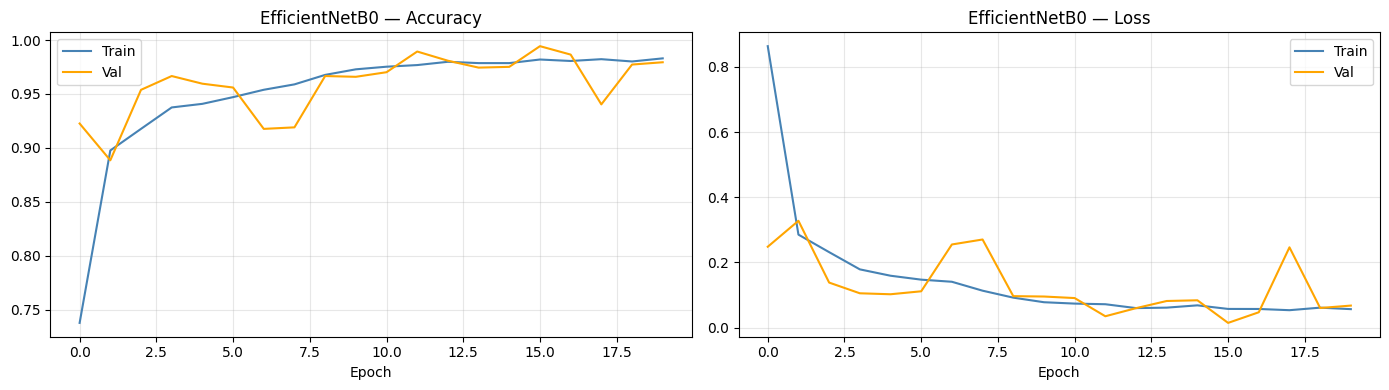

Best val_accuracy: 0.9943181818181818


In [11]:
trained_models = {}
histories      = {}

model, hist = train_model('EfficientNetB0')
trained_models['EfficientNetB0'] = model
histories['EfficientNetB0']      = hist

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
h = hist
axes[0].plot(h['accuracy'],     label='Train', color='steelblue')
axes[0].plot(h['val_accuracy'], label='Val',   color='orange')
axes[0].set_title('EfficientNetB0 — Accuracy')
axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(h['loss'],     label='Train', color='steelblue')
axes[1].plot(h['val_loss'], label='Val',   color='orange')
axes[1].set_title('EfficientNetB0 — Loss')
axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'efficientnet_curves.png'), dpi=150)
plt.show()
print('Best val_accuracy:', max(hist['val_accuracy']))

## 11. Train All Remaining Models

In [12]:
remaining = [n for n in MODEL_CONFIGS if n != 'EfficientNetB0']

for name in remaining:
    model, hist = train_model(name)
    trained_models[name] = model
    histories[name]      = hist

print('\nAll models trained. Best val_accuracy per model:')
for name, h in histories.items():
    print(f'  {name}: {max(h["val_accuracy"]):.4f}')


  MobileNetV2
  Trainable params: 2,982,090
Epoch   1/20  loss=0.8440  acc=0.7212  val_loss=0.4795  val_acc=0.8253
  → saved best model (val_acc=0.8253)
Epoch   2/20  loss=0.3432  acc=0.8768  val_loss=0.4330  val_acc=0.8523
  → saved best model (val_acc=0.8523)
Epoch   3/20  loss=0.2711  acc=0.9047  val_loss=0.1656  val_acc=0.9375
  → saved best model (val_acc=0.9375)
Epoch   4/20  loss=0.2333  acc=0.9105  val_loss=0.5696  val_acc=0.8068
Epoch   5/20  loss=0.2121  acc=0.9242  val_loss=0.7810  val_acc=0.7734
Epoch   6/20  loss=0.1855  acc=0.9322  val_loss=0.6076  val_acc=0.8125
Epoch   7/20  loss=0.1772  acc=0.9366  val_loss=0.3491  val_acc=0.8800
Epoch   8/20  loss=0.1326  acc=0.9533  val_loss=0.0952  val_acc=0.9588
  → saved best model (val_acc=0.9588)
Epoch   9/20  loss=0.1264  acc=0.9583  val_loss=0.1042  val_acc=0.9560
Epoch  10/20  loss=0.1165  acc=0.9598  val_loss=0.1747  val_acc=0.9396
Epoch  11/20  loss=0.1096  acc=0.9604  val_loss=0.0966  val_acc=0.9666
  → saved best model (

  Trainable params: 55,169,834
Epoch   1/20  loss=0.7128  acc=0.7697  val_loss=0.2208  val_acc=0.9226
  → saved best model (val_acc=0.9226)
Epoch   2/20  loss=0.2517  acc=0.9113  val_loss=0.3695  val_acc=0.8878
Epoch   3/20  loss=0.2022  acc=0.9314  val_loss=0.2261  val_acc=0.9141
Epoch   4/20  loss=0.1572  acc=0.9408  val_loss=0.1385  val_acc=0.9545
  → saved best model (val_acc=0.9545)
Epoch   5/20  loss=0.1366  acc=0.9548  val_loss=0.1364  val_acc=0.9531
Epoch   6/20  loss=0.1320  acc=0.9581  val_loss=0.2237  val_acc=0.9276
Epoch   7/20  loss=0.1161  acc=0.9587  val_loss=0.1495  val_acc=0.9482
Epoch   8/20  loss=0.1103  acc=0.9624  val_loss=0.2445  val_acc=0.9297
Epoch   9/20  loss=0.0688  acc=0.9753  val_loss=0.0399  val_acc=0.9822
  → saved best model (val_acc=0.9822)
Epoch  10/20  loss=0.0493  acc=0.9810  val_loss=0.0331  val_acc=0.9872
  → saved best model (val_acc=0.9872)
Epoch  11/20  loss=0.0537  acc=0.9821  val_loss=0.0299  val_acc=0.9865
Epoch  12/20  loss=0.0538  acc=0.980

## 12. Training Curves — All Models

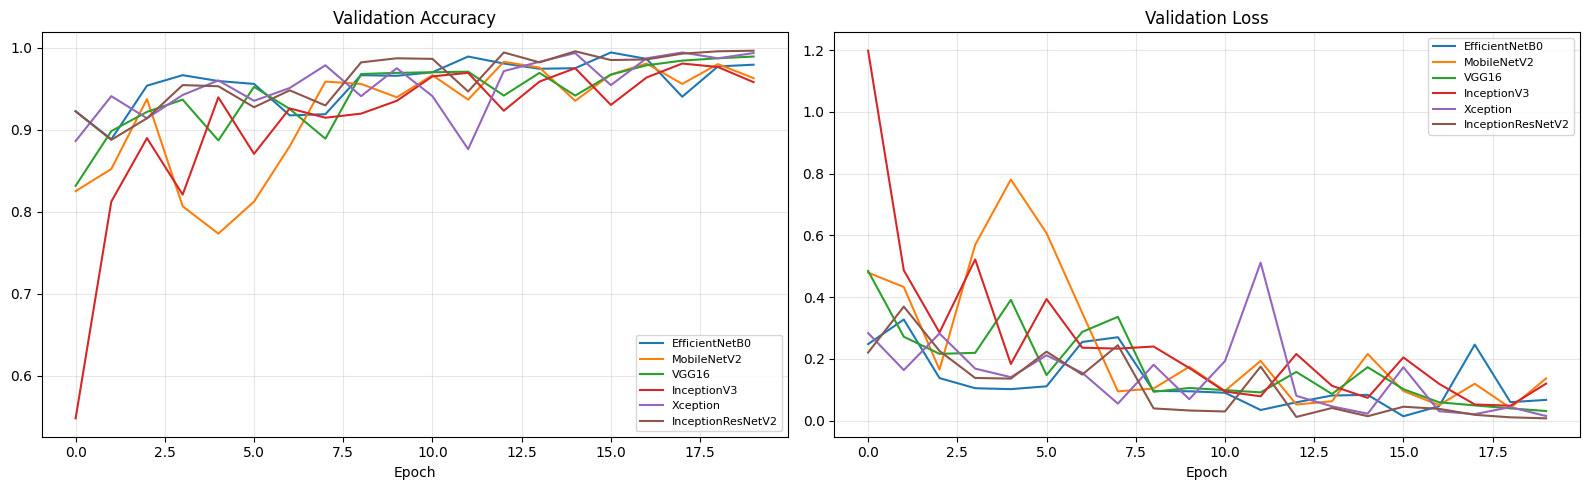

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for name, h in histories.items():
    axes[0].plot(h['val_accuracy'], label=name)
    axes[1].plot(h['val_loss'],     label=name)
for ax, title in zip(axes, ['Validation Accuracy','Validation Loss']):
    ax.set_title(title, fontsize=12); ax.set_xlabel('Epoch')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'all_training_curves.png'), dpi=150)
plt.show()

## 13. Evaluate on Test Set


-- EfficientNetB0  |  Test Accuracy: 0.9975 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       200
        BR-28       1.00      0.99      0.99       200
        BR-29       1.00      1.00      1.00       200
        Beroi       1.00      1.00      1.00       200
    Chinigura       1.00      1.00      1.00       200
    Ghee Bhog       0.99      1.00      0.99       200
 Katari Najir       1.00      0.98      0.99       200
Katari Siddho       1.00      1.00      1.00       200
      Miniket       1.00      1.00      1.00       200
       Swarna       1.00      1.00      1.00       200

     accuracy                           1.00      2000
    macro avg       1.00      1.00      1.00      2000
 weighted avg       1.00      1.00      1.00      2000



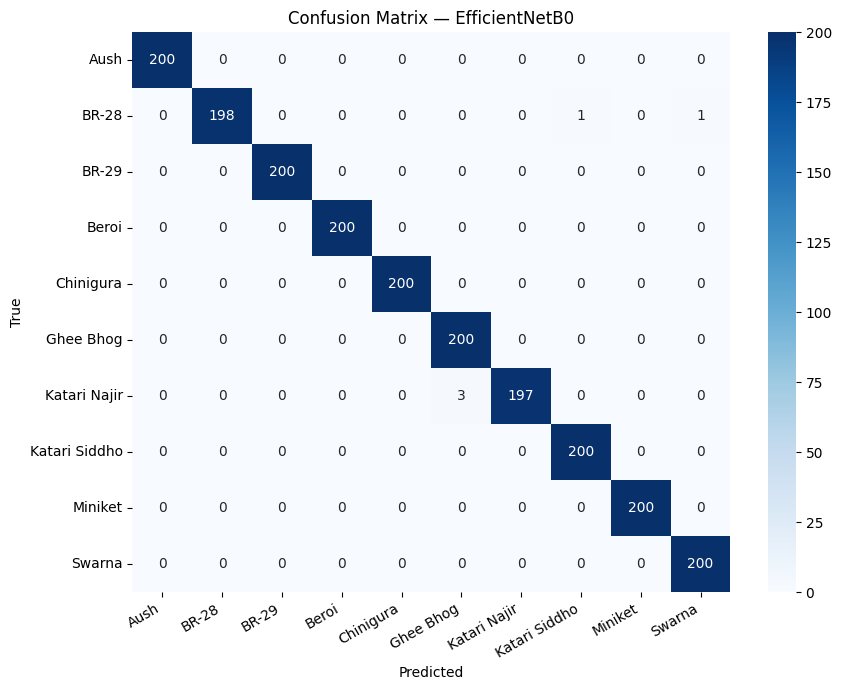


-- MobileNetV2  |  Test Accuracy: 0.9855 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       200
        BR-28       0.99      0.95      0.97       200
        BR-29       0.97      1.00      0.98       200
        Beroi       1.00      1.00      1.00       200
    Chinigura       1.00      0.99      1.00       200
    Ghee Bhog       0.97      0.99      0.98       200
 Katari Najir       0.99      0.94      0.96       200
Katari Siddho       0.96      1.00      0.98       200
      Miniket       1.00      1.00      1.00       200
       Swarna       0.98      0.97      0.98       200

     accuracy                           0.99      2000
    macro avg       0.99      0.99      0.99      2000
 weighted avg       0.99      0.99      0.99      2000



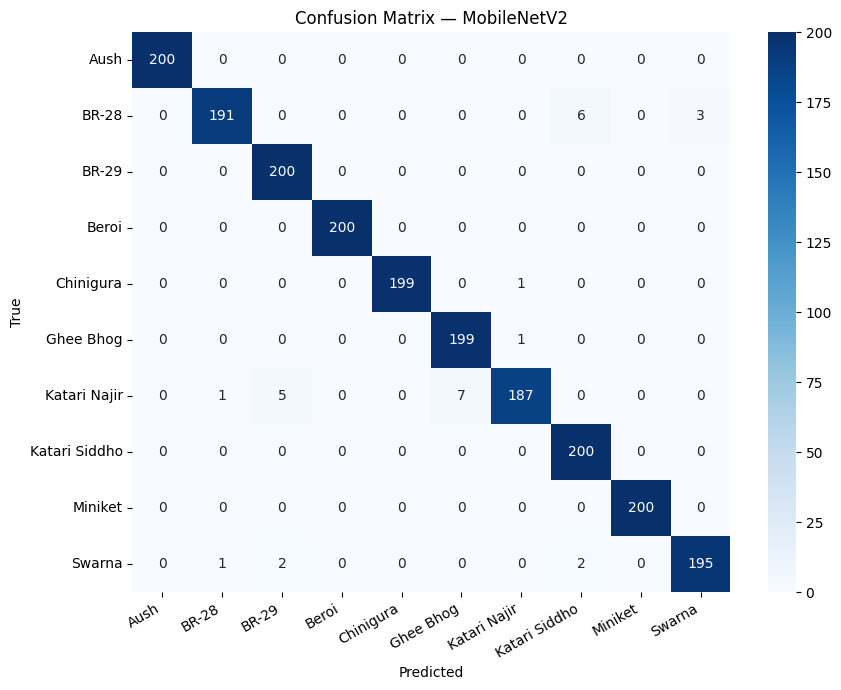


-- VGG16  |  Test Accuracy: 0.9945 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       200
        BR-28       0.98      0.98      0.98       200
        BR-29       1.00      1.00      1.00       200
        Beroi       1.00      1.00      1.00       200
    Chinigura       1.00      1.00      1.00       200
    Ghee Bhog       0.99      1.00      0.99       200
 Katari Najir       1.00      0.98      0.99       200
Katari Siddho       1.00      0.98      0.99       200
      Miniket       1.00      1.00      1.00       200
       Swarna       0.99      1.00      0.99       200

     accuracy                           0.99      2000
    macro avg       0.99      0.99      0.99      2000
 weighted avg       0.99      0.99      0.99      2000



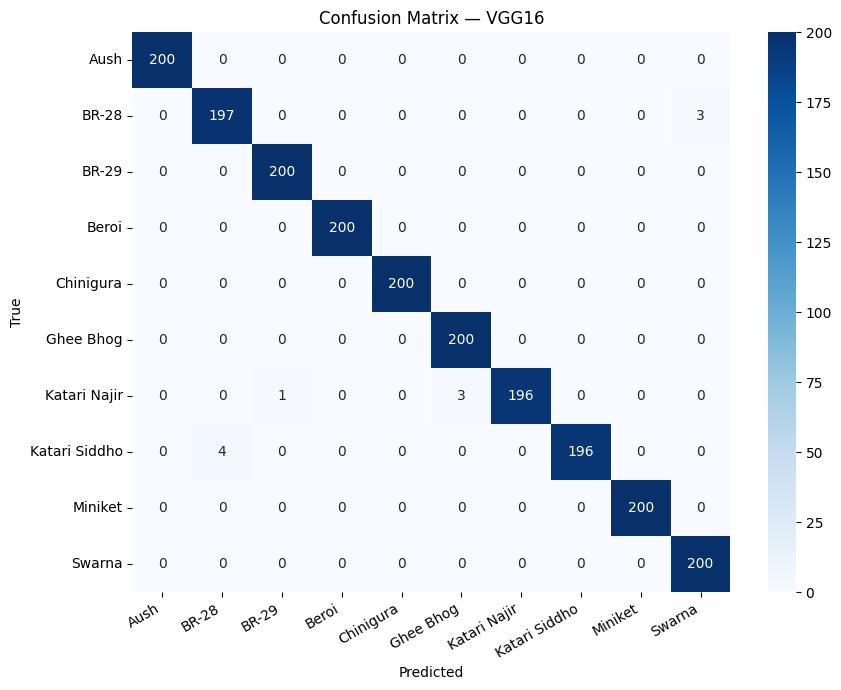


-- InceptionV3  |  Test Accuracy: 0.9865 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       200
        BR-28       0.95      0.99      0.97       200
        BR-29       0.99      0.99      0.99       200
        Beroi       1.00      1.00      1.00       200
    Chinigura       1.00      0.99      1.00       200
    Ghee Bhog       0.96      0.96      0.96       200
 Katari Najir       0.97      0.97      0.97       200
Katari Siddho       1.00      0.95      0.97       200
      Miniket       1.00      1.00      1.00       200
       Swarna       0.99      0.99      0.99       200

     accuracy                           0.99      2000
    macro avg       0.99      0.99      0.99      2000
 weighted avg       0.99      0.99      0.99      2000



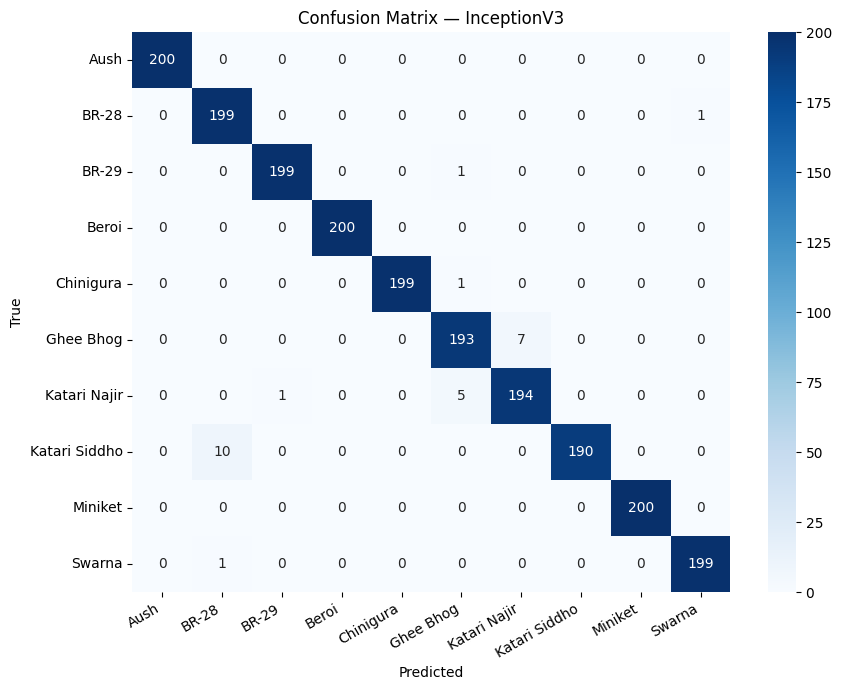


-- Xception  |  Test Accuracy: 0.9940 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       200
        BR-28       1.00      0.95      0.98       200
        BR-29       1.00      0.99      1.00       200
        Beroi       1.00      1.00      1.00       200
    Chinigura       1.00      1.00      1.00       200
    Ghee Bhog       1.00      0.99      0.99       200
 Katari Najir       0.99      1.00      0.99       200
Katari Siddho       0.96      1.00      0.98       200
      Miniket       1.00      1.00      1.00       200
       Swarna       1.00      1.00      1.00       200

     accuracy                           0.99      2000
    macro avg       0.99      0.99      0.99      2000
 weighted avg       0.99      0.99      0.99      2000



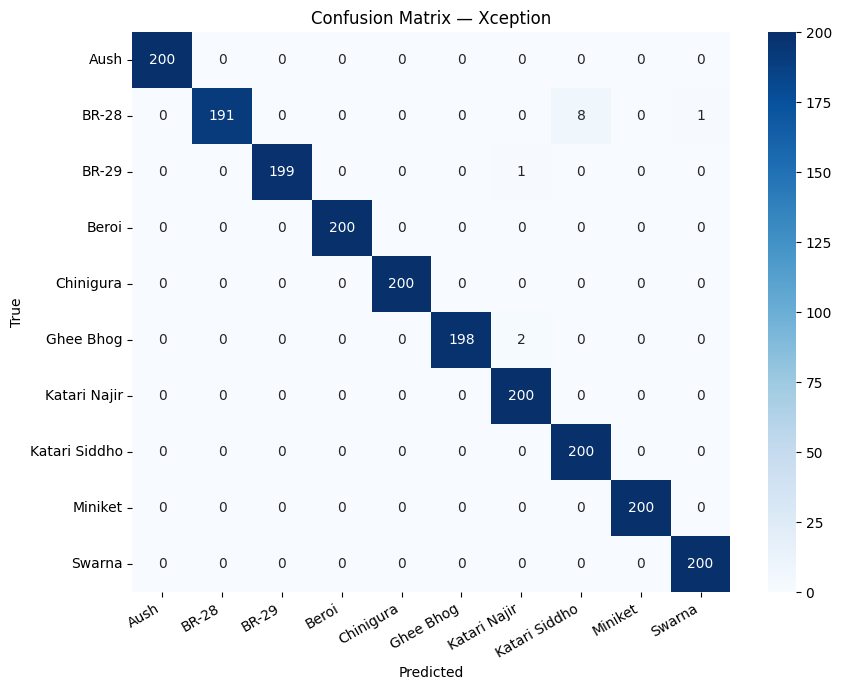


-- InceptionResNetV2  |  Test Accuracy: 0.9990 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       200
        BR-28       1.00      1.00      1.00       200
        BR-29       1.00      1.00      1.00       200
        Beroi       1.00      1.00      1.00       200
    Chinigura       1.00      0.99      1.00       200
    Ghee Bhog       1.00      1.00      1.00       200
 Katari Najir       1.00      1.00      1.00       200
Katari Siddho       1.00      0.99      1.00       200
      Miniket       1.00      1.00      1.00       200
       Swarna       1.00      1.00      1.00       200

     accuracy                           1.00      2000
    macro avg       1.00      1.00      1.00      2000
 weighted avg       1.00      1.00      1.00      2000



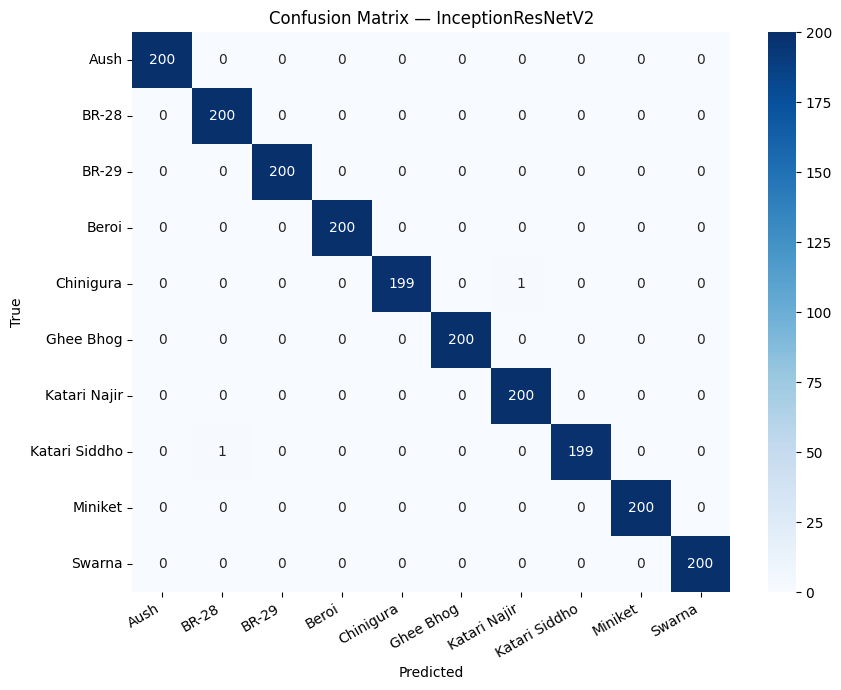

In [22]:
all_reports = {}
all_probas  = {}

def evaluate(model, model_name):
    _, val_dl_unused, test_dl = make_loaders(model_name)

    model.eval()
    all_proba, all_preds, all_true = [], [], []
    with torch.no_grad():
        for imgs, labels in test_dl:
            imgs = imgs.to(DEVICE, non_blocking=True)
            outputs = model(imgs)
            if isinstance(outputs, tuple):
                outputs = outputs[0]
            proba = torch.softmax(outputs, dim=1).cpu().numpy()
            all_proba.append(proba)
            all_preds.append(proba.argmax(axis=1))
            all_true.append(labels.numpy())

    proba  = np.vstack(all_proba)
    y_pred = np.concatenate(all_preds)
    y_true = np.concatenate(all_true)

    rep = classification_report(
        y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)

    print(f'\n-- {model_name}  |  Test Accuracy: {rep["accuracy"]:.4f} --')
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

    cm_arr = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(cm_arr, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f'Confusion Matrix — {model_name}', fontsize=12)
    ax.set_ylabel('True'); ax.set_xlabel('Predicted')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'cm_{model_name}.png'), dpi=150)
    plt.show()
    return rep, proba

for name, model in trained_models.items():
    rep, proba = evaluate(model, name)
    all_reports[name] = rep
    all_probas[name]  = proba

## 14. Ensemble — Hard / Soft / Weighted Voting

Weights: {'EfficientNetB0': np.float64(0.1674), 'MobileNetV2': np.float64(0.1655), 'VGG16': np.float64(0.1666), 'InceptionV3': np.float64(0.1652), 'Xception': np.float64(0.1674), 'InceptionResNetV2': np.float64(0.1678)}

-- Hard Voting  |  Accuracy: 0.9990 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       200
        BR-28       1.00      0.99      1.00       200
        BR-29       1.00      1.00      1.00       200
        Beroi       1.00      1.00      1.00       200
    Chinigura       1.00      1.00      1.00       200
    Ghee Bhog       1.00      1.00      1.00       200
 Katari Najir       1.00      0.99      1.00       200
Katari Siddho       1.00      1.00      1.00       200
      Miniket       1.00      1.00      1.00       200
       Swarna       1.00      1.00      1.00       200

     accuracy                           1.00      2000
    macro avg       1.00      1.00      1.00      2000
 weighted avg       1.0

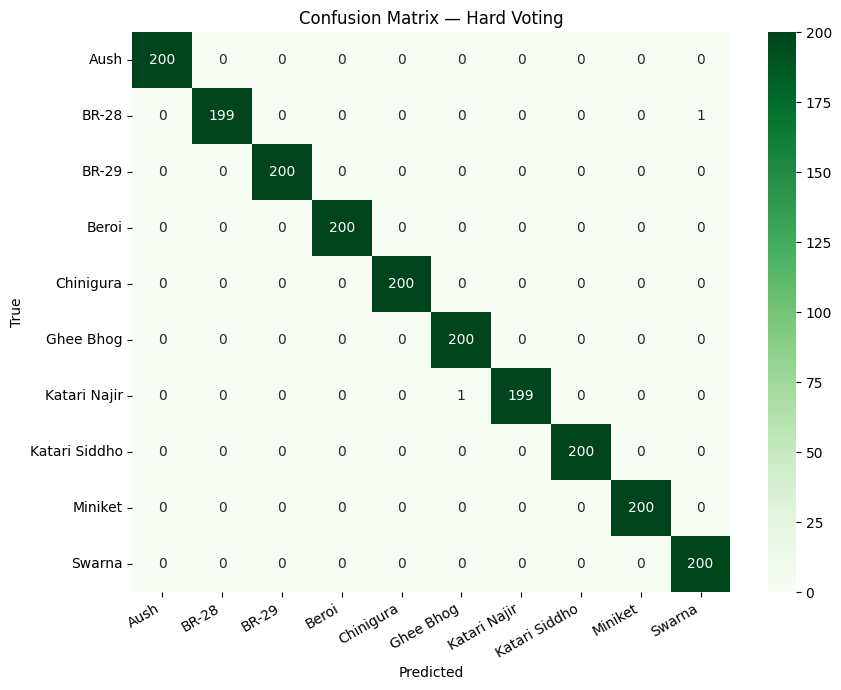


-- Soft Voting  |  Accuracy: 0.9995 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       200
        BR-28       1.00      0.99      1.00       200
        BR-29       1.00      1.00      1.00       200
        Beroi       1.00      1.00      1.00       200
    Chinigura       1.00      1.00      1.00       200
    Ghee Bhog       1.00      1.00      1.00       200
 Katari Najir       1.00      1.00      1.00       200
Katari Siddho       1.00      1.00      1.00       200
      Miniket       1.00      1.00      1.00       200
       Swarna       1.00      1.00      1.00       200

     accuracy                           1.00      2000
    macro avg       1.00      1.00      1.00      2000
 weighted avg       1.00      1.00      1.00      2000



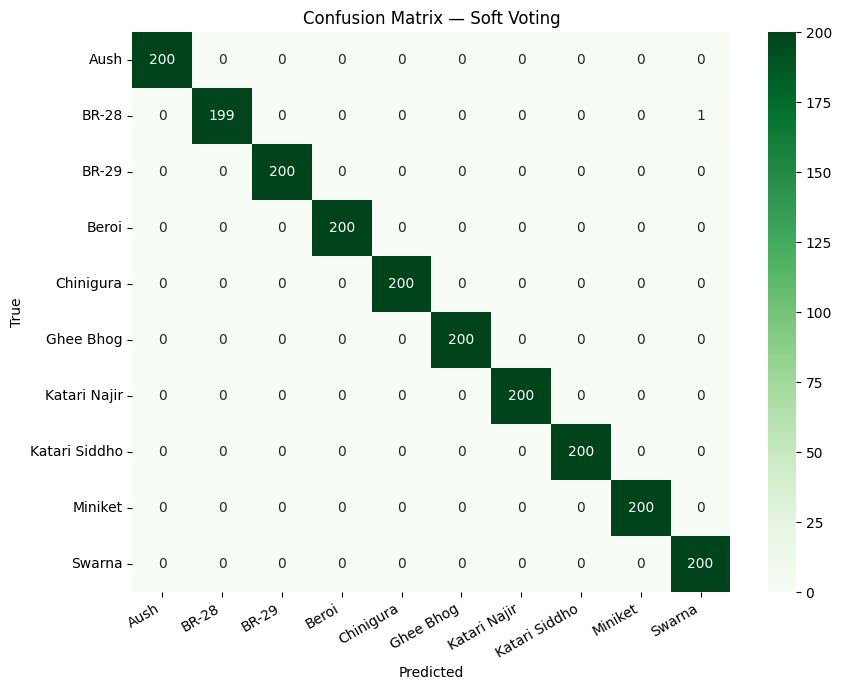


-- Weighted Voting  |  Accuracy: 0.9995 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       200
        BR-28       1.00      0.99      1.00       200
        BR-29       1.00      1.00      1.00       200
        Beroi       1.00      1.00      1.00       200
    Chinigura       1.00      1.00      1.00       200
    Ghee Bhog       1.00      1.00      1.00       200
 Katari Najir       1.00      1.00      1.00       200
Katari Siddho       1.00      1.00      1.00       200
      Miniket       1.00      1.00      1.00       200
       Swarna       1.00      1.00      1.00       200

     accuracy                           1.00      2000
    macro avg       1.00      1.00      1.00      2000
 weighted avg       1.00      1.00      1.00      2000



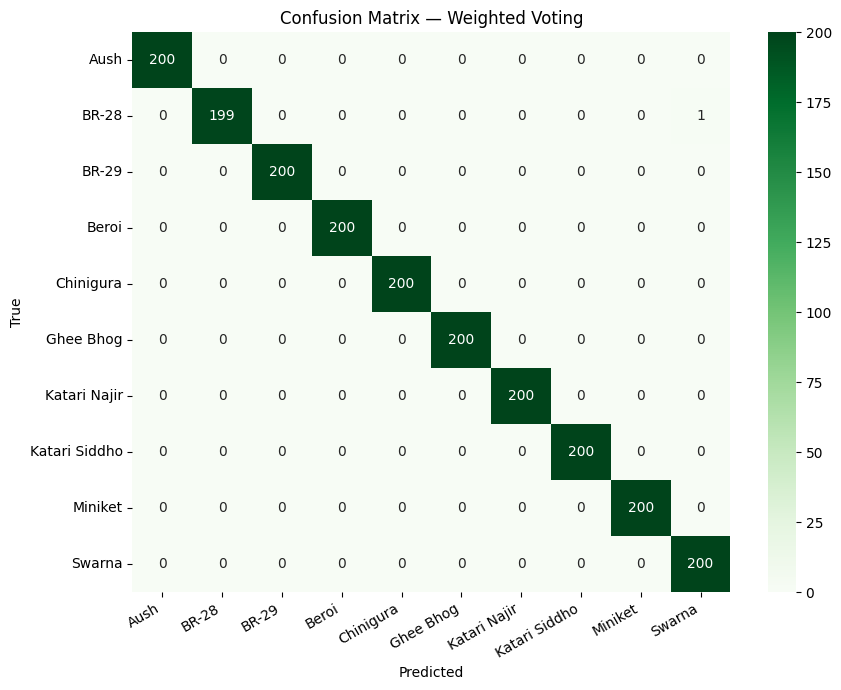

In [23]:
# Re-collect ground truth from test set (consistent order)
y_test_arr = np.concatenate([
    np.array([lbl for _, lbl in make_loaders(list(trained_models.keys())[0])[2].dataset])
])

preds_stack   = np.array([np.argmax(p, axis=1) for p in all_probas.values()])
hard_preds, _ = stats.mode(preds_stack, axis=0, keepdims=False)
hard_preds    = np.array(hard_preds).flatten()

soft_avg   = np.mean(list(all_probas.values()), axis=0)
soft_preds = np.argmax(soft_avg, axis=1)

val_accs = np.array([max(histories[n]['val_accuracy']) for n in trained_models])
weights_ens = val_accs / val_accs.sum()
print('Weights:', dict(zip(trained_models.keys(), weights_ens.round(4))))

weighted_avg   = np.average(list(all_probas.values()), axis=0, weights=weights_ens)
weighted_preds = np.argmax(weighted_avg, axis=1)

for ens_name, preds, proba in [
    ('Hard Voting',     hard_preds,     None),
    ('Soft Voting',     soft_preds,     soft_avg),
    ('Weighted Voting', weighted_preds, weighted_avg),
]:
    rep = classification_report(
        y_test, preds, target_names=CLASS_NAMES, output_dict=True)
    all_reports[ens_name] = rep
    if proba is not None: all_probas[ens_name] = proba
    print(f'\n-- {ens_name}  |  Accuracy: {rep["accuracy"]:.4f} --')
    print(classification_report(y_test, preds, target_names=CLASS_NAMES))
    cm_arr = confusion_matrix(y_test, preds)
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(cm_arr, annot=True, fmt='d', cmap='Greens',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    safe = ens_name.replace(' ','_')
    ax.set_title(f'Confusion Matrix — {ens_name}', fontsize=12)
    ax.set_ylabel('True'); ax.set_xlabel('Predicted')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'cm_{safe}.png'), dpi=150)
    plt.show()

## 15. ROC-AUC Curves

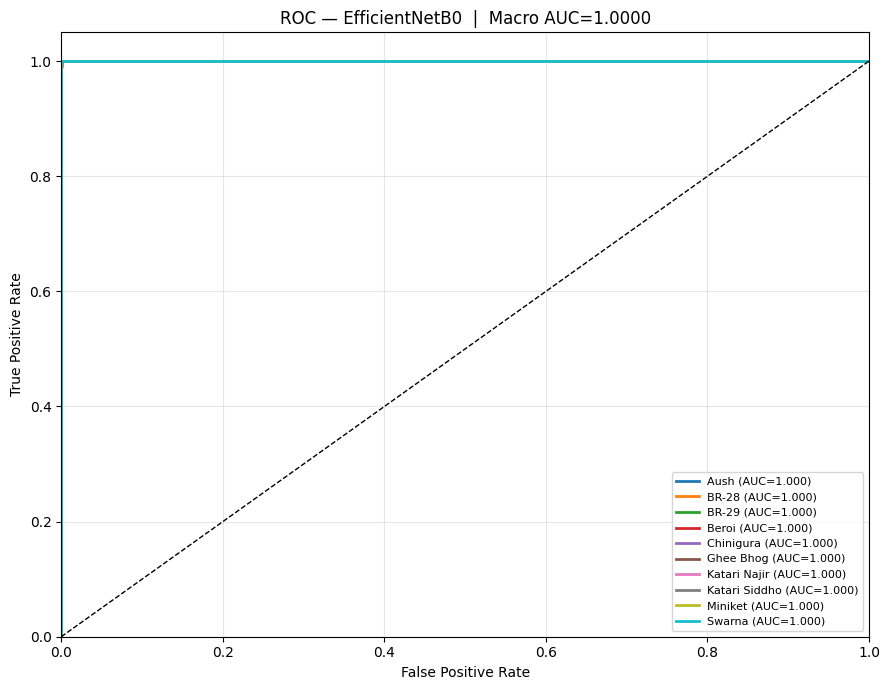

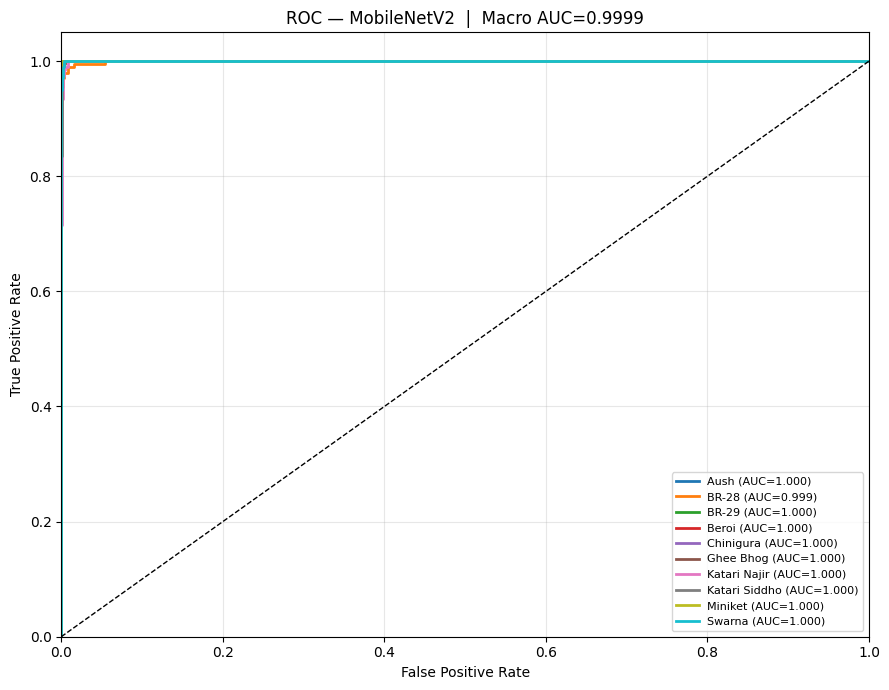

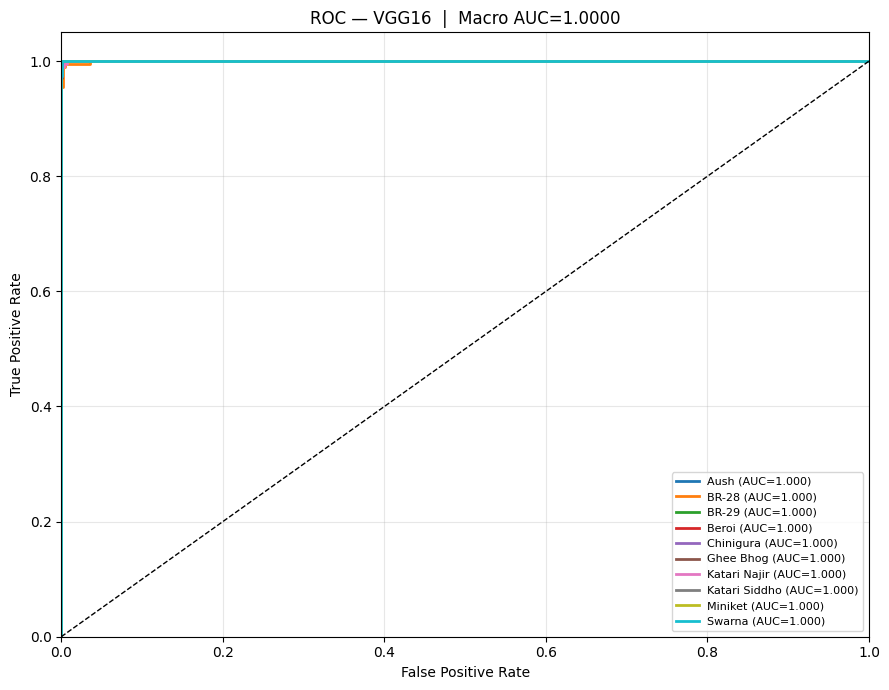

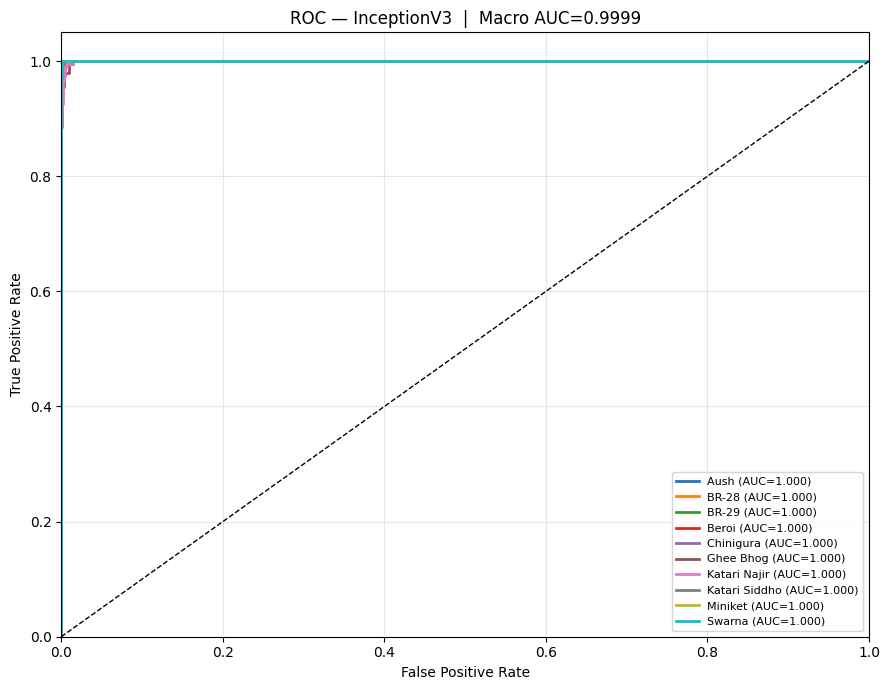

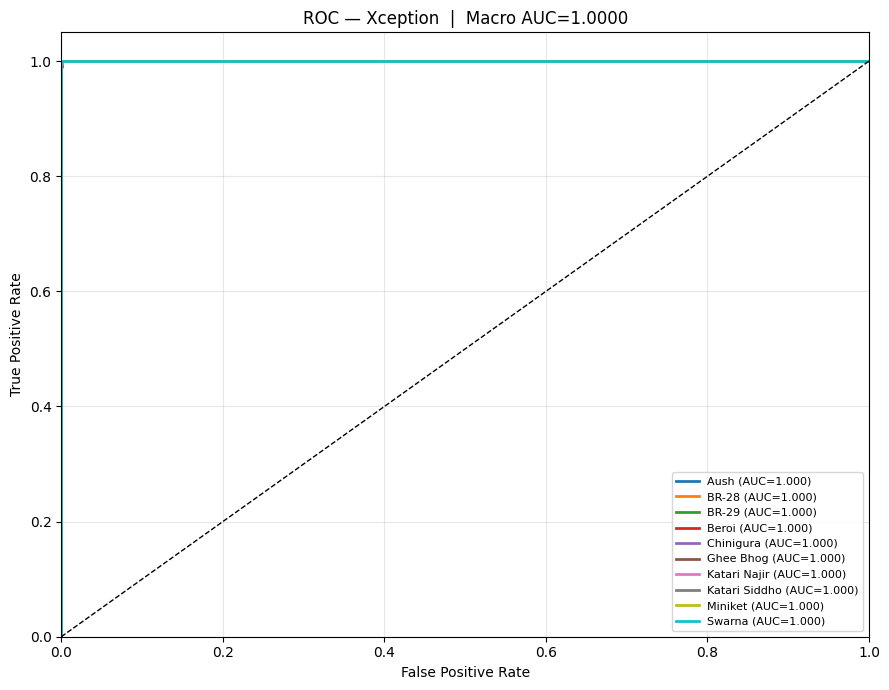

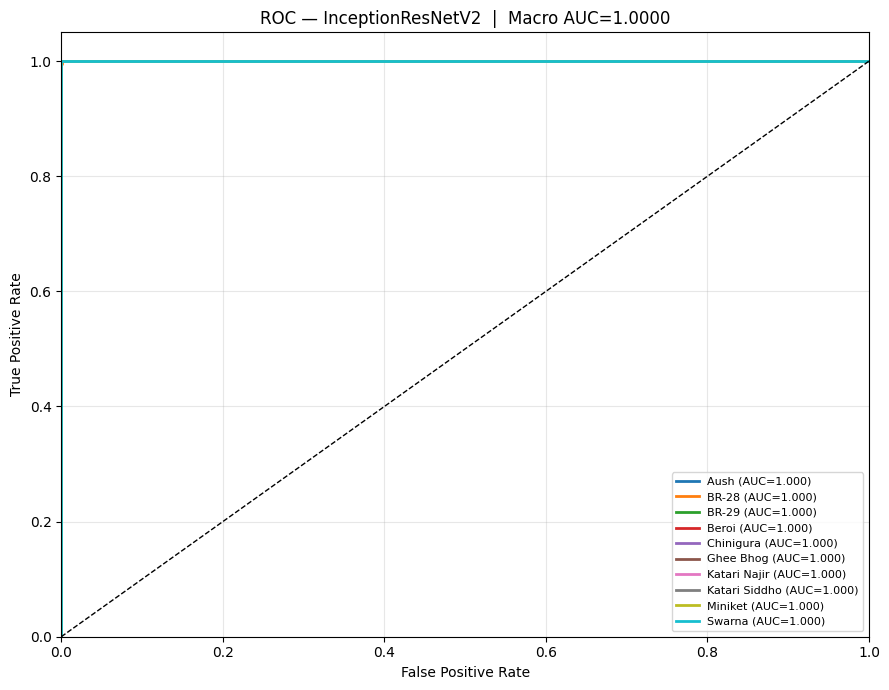

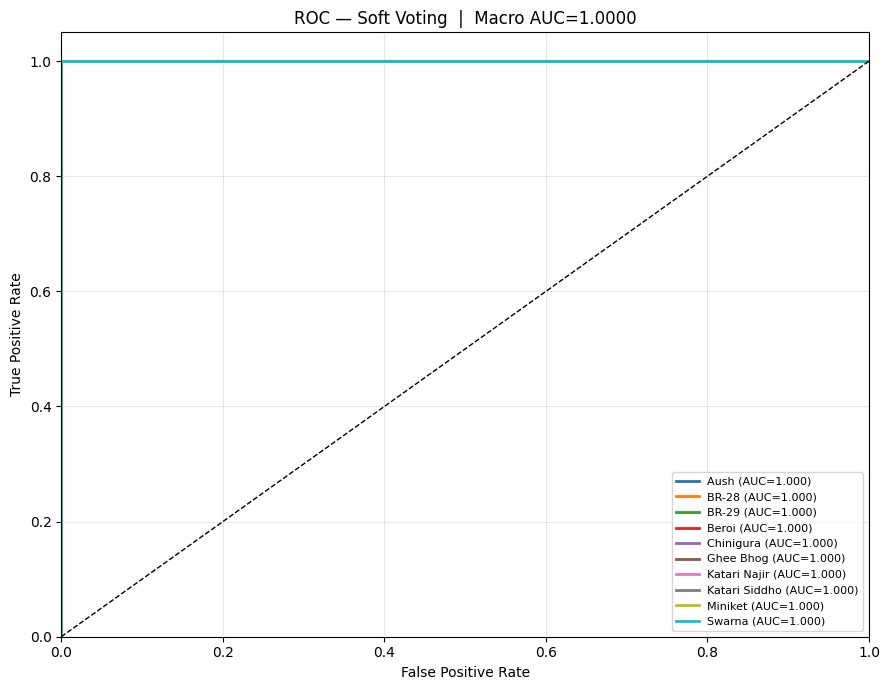

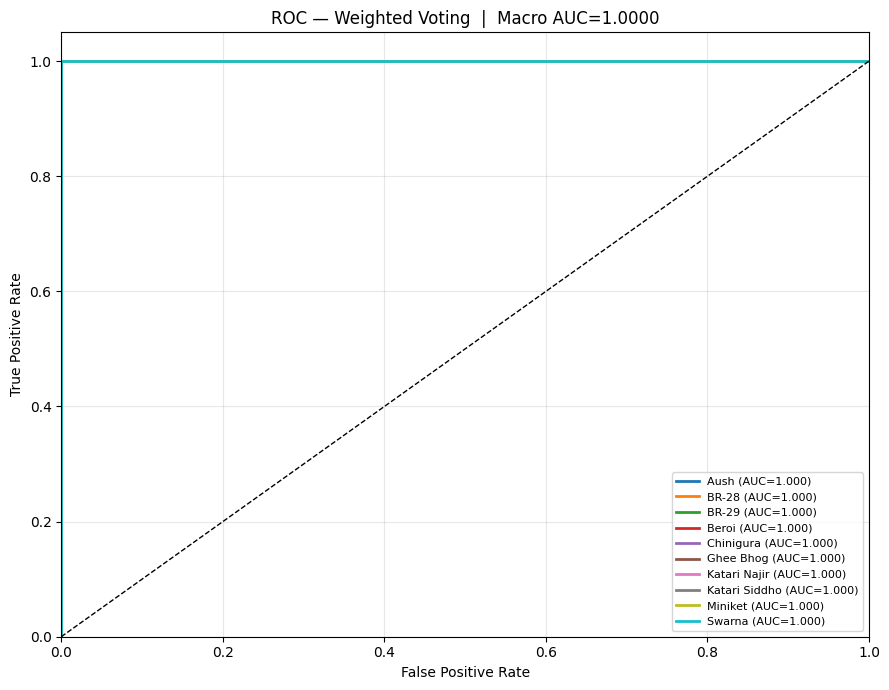

In [24]:
def plot_roc(y_true, y_proba, title):
    y_bin  = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    colors = plt.cm.tab10(np.linspace(0, 1, NUM_CLASSES))
    fig, ax = plt.subplots(figsize=(9, 7))
    aucs = []
    for i, (cls, col) in enumerate(zip(CLASS_NAMES, colors)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
        a = auc(fpr, tpr); aucs.append(a)
        ax.plot(fpr, tpr, color=col, lw=2, label=f'{cls} (AUC={a:.3f})')
    ax.plot([0,1],[0,1],'k--',lw=1)
    ax.set_xlim([0,1]); ax.set_ylim([0,1.05])
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'ROC — {title}  |  Macro AUC={np.mean(aucs):.4f}')
    ax.legend(loc='lower right', fontsize=8); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    safe = title.replace(' ','_').replace('(','').replace(')','').replace('/','_')
    plt.savefig(os.path.join(OUTPUT_DIR, f'roc_{safe}.png'), dpi=150)
    plt.show()
    all_reports[title]['macro_auc'] = round(float(np.mean(aucs)), 4)

for name, proba in all_probas.items():
    if name in all_reports:
        plot_roc(y_test, proba, name)

## 16. Grad-CAM

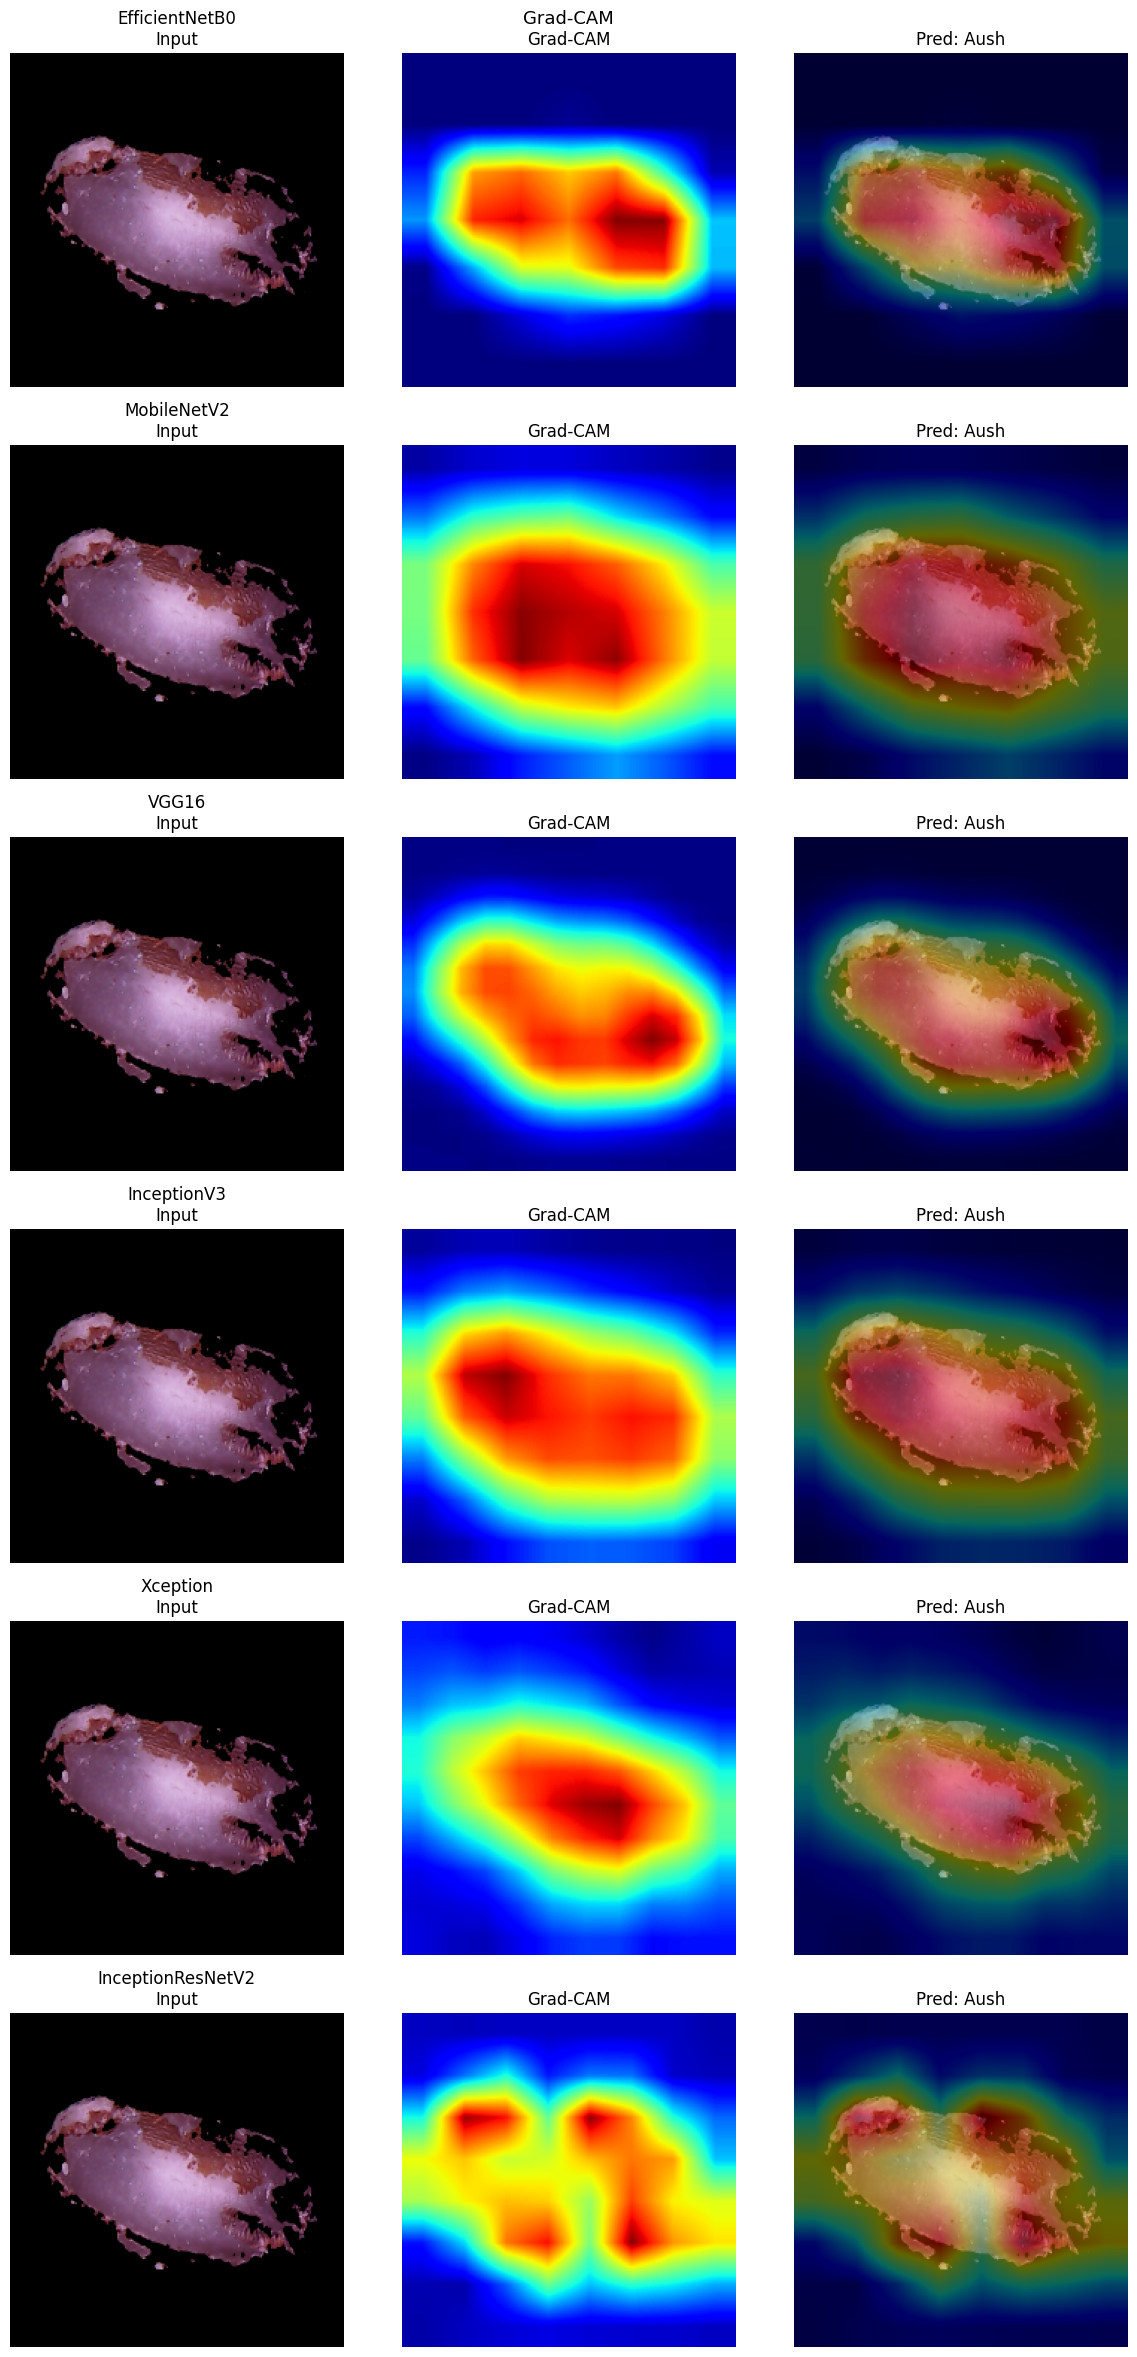

In [25]:
# Last conv layer name per architecture (torchvision internal naming)
LAST_CONV_PT = {
    'EfficientNetB0':    'features.8',
    'MobileNetV2':       'features.18',
    'VGG16':             'features.29',
    'InceptionV3':       'Mixed_7c',
    'Xception':          'backbone.act4',          # timm
    'InceptionResNetV2': 'backbone.conv2d_7b',      # timm
}

def get_gradcam_pt(img_uint8, model, conv_layer_name, model_name):
    _, mean, std, inp_size = MODEL_CONFIGS[model_name]
    tfm = make_transforms(mean, std, inp_size, train=False)
    inp = tfm(img_uint8).unsqueeze(0).to(DEVICE)

    # Hook
    activation, gradient = {}, {}

    def fwd_hook(module, inp_, out):
        activation['fmap'] = out

    def bwd_hook(module, grad_in, grad_out):
        gradient['grad'] = grad_out[0]

    # Resolve layer by name
    layer = model
    for part in conv_layer_name.split('.'):
        try:
            layer = getattr(layer, part)
        except AttributeError:
            layer = layer[int(part)]

    fh = layer.register_forward_hook(fwd_hook)
    bh = layer.register_backward_hook(bwd_hook)

    model.eval()
    output = model(inp)
    if isinstance(output, tuple): output = output[0]
    pred_idx = output.argmax(dim=1).item()
    model.zero_grad()
    output[0, pred_idx].backward()

    fh.remove(); bh.remove()

    fmap = activation['fmap'][0].detach().cpu().numpy()  # (C, H, W)
    grad = gradient['grad'][0].detach().cpu().numpy()    # (C, H, W)
    pooled = grad.mean(axis=(1, 2))                      # (C,)
    cam = np.maximum(np.einsum('c,chw->hw', pooled, fmap), 0)
    cam = cam / (cam.max() + 1e-8)
    hm  = cv2.resize(cam, IMG_SIZE)
    jet     = mpl_cm.jet(np.uint8(255 * hm))[:, :, :3]
    orig    = img_uint8 / 255.0
    overlay = np.clip(jet * 0.4 + orig * 0.6, 0, 1)
    return orig, jet, overlay, pred_idx

sample_img = segment_grain(aug_paths[0])
n = len(trained_models)
fig, axes = plt.subplots(n, 3, figsize=(12, 4*n))
if n == 1: axes = axes[np.newaxis, :]
for row, (name, model) in enumerate(trained_models.items()):
    try:
        orig, hm, overlay, pred = get_gradcam_pt(
            sample_img, model, LAST_CONV_PT[name], name)
        axes[row,0].imshow(orig);    axes[row,0].set_title(f'{name}\nInput')
        axes[row,1].imshow(hm);      axes[row,1].set_title('Grad-CAM')
        axes[row,2].imshow(overlay); axes[row,2].set_title(f'Pred: {CLASS_NAMES[pred]}')
    except Exception as e:
        axes[row,0].set_title(f'{name}: {e}', fontsize=7)
    for ax in axes[row]: ax.axis('off')
plt.suptitle('Grad-CAM', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'gradcam_all.png'), dpi=150)
plt.show()

## 17. LIME

  0%|          | 0/300 [00:00<?, ?it/s]

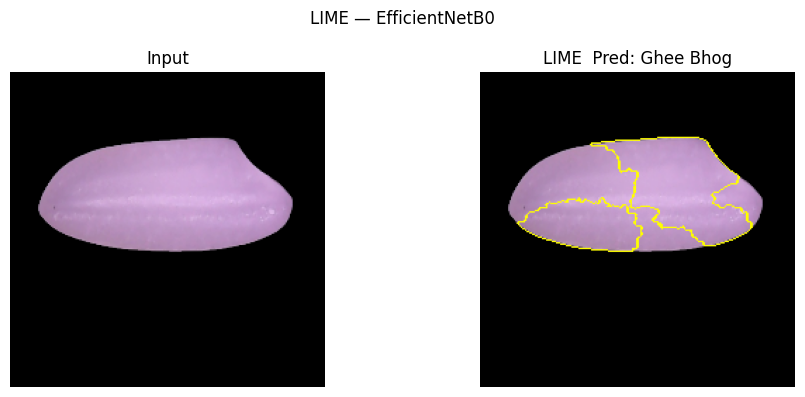

  0%|          | 0/300 [00:00<?, ?it/s]

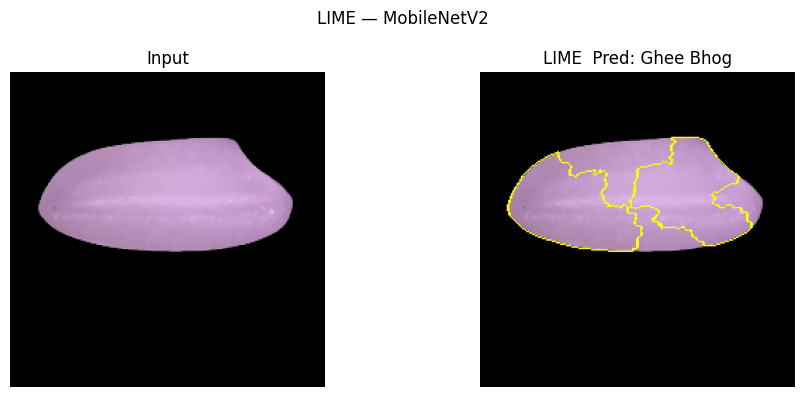

  0%|          | 0/300 [00:00<?, ?it/s]

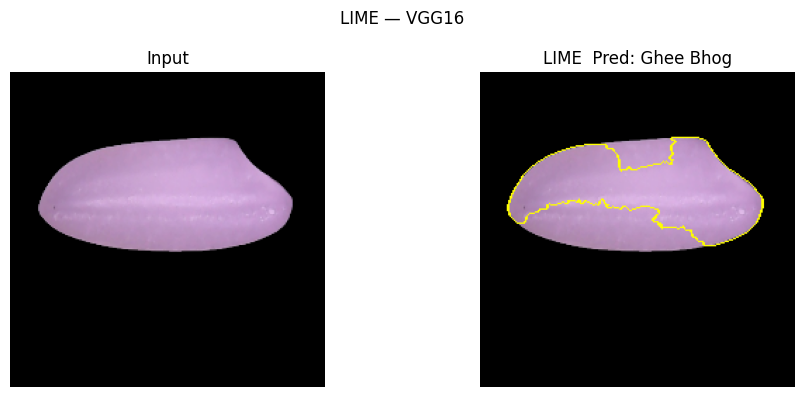

  0%|          | 0/300 [00:00<?, ?it/s]

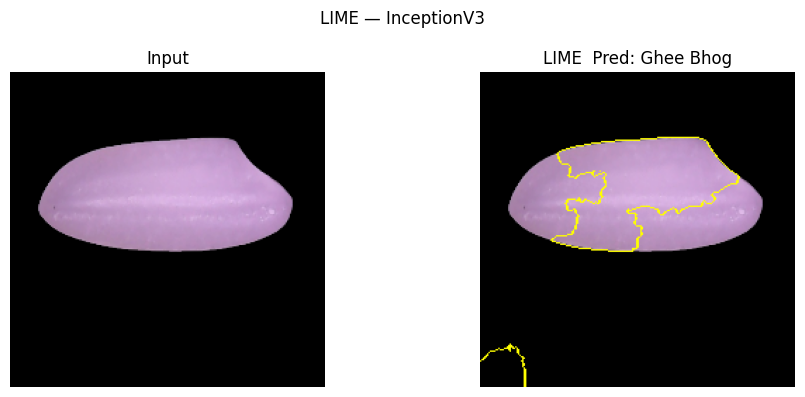

  0%|          | 0/300 [00:00<?, ?it/s]

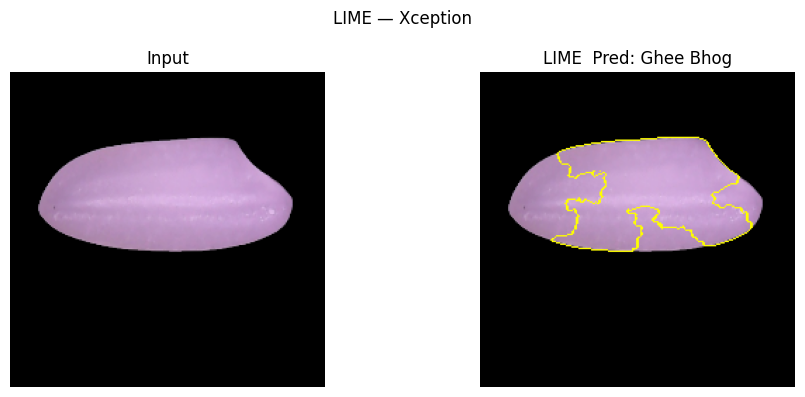

  0%|          | 0/300 [00:00<?, ?it/s]

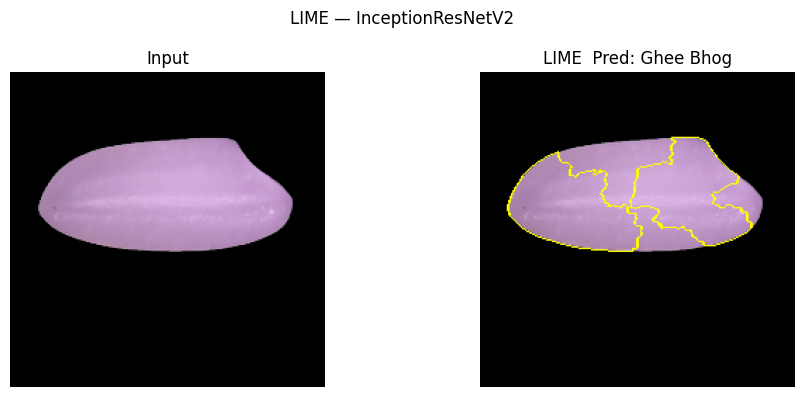

In [31]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

def explain_lime(img_uint8, model, model_name, num_samples=300):
    _, mean, std, inp_size = MODEL_CONFIGS[model_name]
    tfm = make_transforms(mean, std, inp_size, train=False)

    def predict_fn(imgs_np):
        # imgs_np: (N, H, W, 3) uint8
        batch = torch.stack([tfm(img) for img in imgs_np]).to(DEVICE)
        with torch.no_grad():
            out = model(batch)
            if isinstance(out, tuple): out = out[0]
        return torch.softmax(out, dim=1).cpu().numpy()

    explainer = lime_image.LimeImageExplainer()
    exp = explainer.explain_instance(
        img_uint8, predict_fn,
        top_labels=NUM_CLASSES, hide_color=0, num_samples=num_samples
    )
    top = exp.top_labels[0]
    temp, mask = exp.get_image_and_mask(
        top, positive_only=True, num_features=5, hide_rest=False)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(img_uint8); axes[0].set_title('Input'); axes[0].axis('off')
    axes[1].imshow(mark_boundaries(np.clip(temp/255.0, 0, 1), mask))
    axes[1].set_title(f'LIME  Pred: {CLASS_NAMES[top]}')
    axes[1].axis('off')
    plt.suptitle(f'LIME — {model_name}', fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'lime', f'lime_{model_name}.png'), dpi=150)
    plt.show()

sample_img = segment_grain(aug_paths[4382])
for name, model in trained_models.items():
    explain_lime(sample_img, model, name)

## 18. Results Summary

            Model  Accuracy  Precision  Recall     F1    AUC
      Soft Voting    0.9995     0.9995  0.9995 0.9995 1.0000
  Weighted Voting    0.9995     0.9995  0.9995 0.9995 1.0000
InceptionResNetV2    0.9990     0.9990  0.9990 0.9990 1.0000
      Hard Voting    0.9990     0.9990  0.9990 0.9990    NaN
   EfficientNetB0    0.9975     0.9975  0.9975 0.9975 1.0000
            VGG16    0.9945     0.9946  0.9945 0.9945 1.0000
         Xception    0.9940     0.9942  0.9940 0.9940 1.0000
      InceptionV3    0.9865     0.9868  0.9865 0.9865 0.9999
      MobileNetV2    0.9855     0.9858  0.9855 0.9854 0.9999


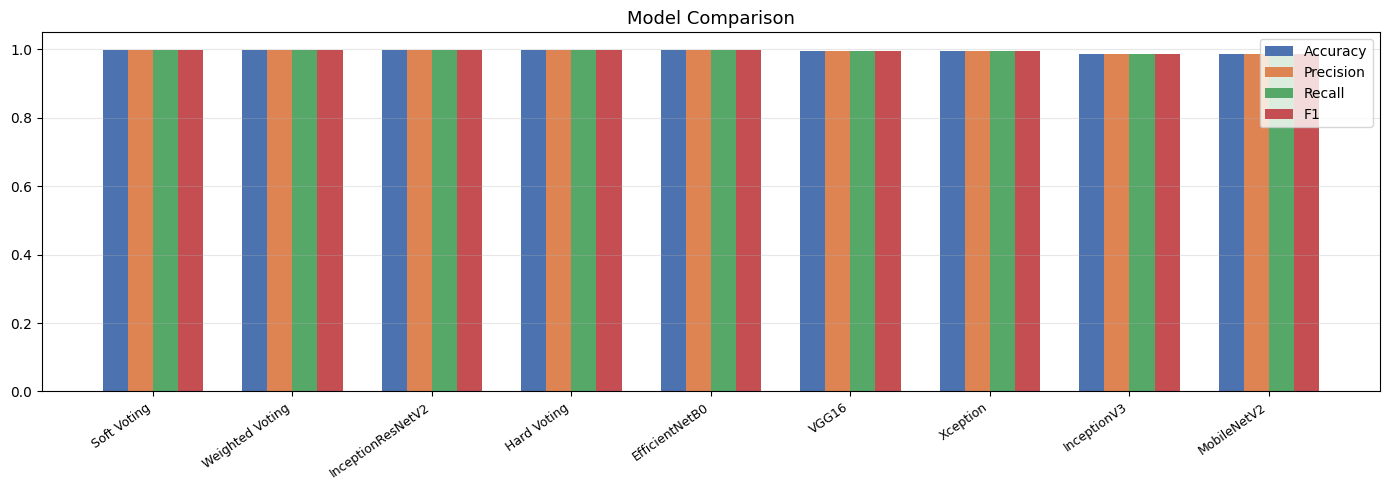

In [27]:
# NOTE: Results below are only reliable when EPOCHS=20 with early stopping.
# With EPOCHS=3 (debug run), models like InceptionV3 are significantly undertrained.

rows = []
for name, rep in all_reports.items():
    row = {
        'Model':     name,
        'Accuracy':  round(rep['accuracy'], 4),
        'Precision': round(rep['macro avg']['precision'], 4),
        'Recall':    round(rep['macro avg']['recall'], 4),
        'F1':        round(rep['macro avg']['f1-score'], 4),
    }
    if 'macro_auc' in rep: row['AUC'] = rep['macro_auc']
    rows.append(row)

df = (pd.DataFrame(rows)
        .sort_values('Accuracy', ascending=False)
        .reset_index(drop=True))
print(df.to_string(index=False))
df.to_csv(os.path.join(OUTPUT_DIR, 'results_summary.csv'), index=False)

fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(df)); w = 0.18
ax.bar(x-1.5*w, df['Accuracy'],  w, label='Accuracy',  color='#4C72B0')
ax.bar(x-0.5*w, df['Precision'], w, label='Precision', color='#DD8452')
ax.bar(x+0.5*w, df['Recall'],    w, label='Recall',    color='#55A868')
ax.bar(x+1.5*w, df['F1'],        w, label='F1',        color='#C44E52')
ax.set_xticks(x)
ax.set_xticklabels(df['Model'], rotation=35, ha='right', fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_title('Model Comparison', fontsize=13)
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'model_comparison.png'), dpi=150)
plt.show()

## 19. Single Image Inference

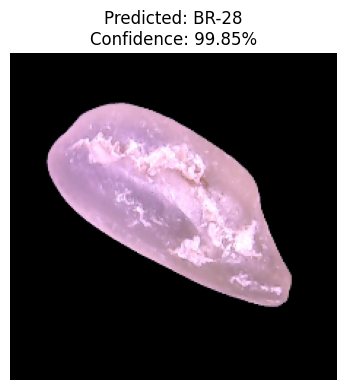

{'class': 'BR-28', 'confidence': 0.9985}


In [ ]:
def predict(image_path, voting='weighted'):
    img_uint8 = segment_grain(image_path)
    probas = []
    for name, model in trained_models.items():
        _, mean, std, inp_size = MODEL_CONFIGS[name]
        tfm = make_transforms(mean, std, inp_size, train=False)
        inp = tfm(img_uint8).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            out = model(inp)
            if isinstance(out, tuple): out = out[0]
        probas.append(torch.softmax(out, dim=1).cpu().numpy()[0])
    probas = np.array(probas)

    if voting == 'hard':
        preds = np.argmax(probas, axis=1)
        mode_result = stats.mode(preds)
        idx   = int(mode_result.mode[0] if hasattr(mode_result.mode, '__len__') else mode_result.mode)
        conf  = float((preds == idx).mean())
    elif voting == 'weighted':
        avg  = np.average(probas, axis=0, weights=weights_ens)
        idx  = int(np.argmax(avg)); conf = float(avg[idx])
    else:
        avg  = probas.mean(axis=0)
        idx  = int(np.argmax(avg)); conf = float(avg[idx])

    plt.figure(figsize=(4, 4))
    plt.imshow(img_uint8)
    plt.title(f'Predicted: {CLASS_NAMES[idx]}\nConfidence: {conf:.2%}')
    plt.axis('off'); plt.tight_layout(); plt.show()
    return {'class': CLASS_NAMES[idx], 'confidence': round(conf, 4)}

print(predict(aug_paths[900]))


---
## Done. Outputs saved to `./outputs/`